# ACC_Modeling — Stage 2 Final (SINDy Benchmark)
**`stage2final`: Whole-Vehicle Planar Force & Friction-Ellipse Identification ($[a_y, a_x, v, \eta_P] \to \dot{r}$)**

This notebook establishes the final **Stage 2 SINDy** baseline benchmark for direct comparison with **Stage 3** (single-wheel physics modeling) and **Stage 4** (full-chassis nonlinear modeling).

### Scope & Configuration
- **Vehicle**: Audi R8 LMS GT3 Evo II (`configs/cars/audi_r8_gt3_evo2/vehicle.yaml`)
- **Setup**: `R8_A` (`configs/cars/audi_r8_gt3_evo2/setups/Barcelona/r8_A.yaml`)
- **Telemetry**: 10L Hotlap Baseline (`data/calibration/baseline.csv`, 200 Hz, fixed 10L fuel, no race laps)
- **Curation**: Savitzky-Golay (`window=21, poly=3`) smoothing & analytical differentiation ($\dot{r}, \dot{a}_y$), tire-pressure grip factor $\eta_P(t)$
- **Regression**: PySINDy `STLSQ` (`threshold=0.01`, `alpha=0.05`) on the 8-term physics-informed planar force library

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src.cli import run_pipeline

print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Run Stage 2 Final SINDy Pipeline (GT3 10L Hotlap Baseline)

In [2]:
config_path = "configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A__hotlap_10l.yaml"
report = run_pipeline(config_path)

print("Identified ODE:", report["equation"])
print(f"Samples: {report['clean_metrics']['n_samples']}")
print(f"R^2:     {report['clean_metrics']['r2']:.6f}")
print(f"RMSE:    {report['clean_metrics']['rmse']:.6f} rad/s^2")
print(f"MAE:     {report['clean_metrics']['mae']:.6f} rad/s^2")

INFO: Running experiment: stage2final_barcelona_gt3_r8_A_hotlap_10l (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 21367 -> 21367 rows)


INFO: Identified ODE: dr/dt = +2.52717 * r -0.45930 * a_y +0.29893 * a_y_dot -4.04541 * a_y_dot/v +0.01401 * a_y-v*r -0.10122 * a_y*|a_x| +0.04118 * a_y*(a_x^2+a_y^2)/eta_P^2 -2.21953 * r*|r|


INFO: Clean Practice R^2=0.1701 | RMSE=1.0775 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Artifacts saved to outputs/stage2final_barcelona_gt3_r8_A_hotlap_10l


Identified ODE: dr/dt = +2.52717 * r -0.45930 * a_y +0.29893 * a_y_dot -4.04541 * a_y_dot/v +0.01401 * a_y-v*r -0.10122 * a_y*|a_x| +0.04118 * a_y*(a_x^2+a_y^2)/eta_P^2 -2.21953 * r*|r|
Samples: 21367
R^2:     0.170092
RMSE:    1.077495 rad/s^2
MAE:     0.678827 rad/s^2


## 2. Benchmark Summary & Statistical Diagnostics

In [3]:
diag = report["clean_metrics"]["diagnostics"]
summary_df = pd.DataFrame([{
    "Experiment": report["experiment"],
    "Samples": report["clean_metrics"]["n_samples"],
    "R2": report["clean_metrics"]["r2"],
    "RMSE (rad/s^2)": report["clean_metrics"]["rmse"],
    "MAE (rad/s^2)": report["clean_metrics"]["mae"],
    "Within ±3σ (%)": diag["within_3sigma_pct"],
    "Skewness": diag["skewness"],
    "Excess Kurtosis": diag["excess_kurtosis"],
}])
display(Markdown("### Stage 2 Final Benchmark Metrics"))
display(summary_df)

display(Markdown("### Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(report["bootstrap"]["terms"]))

display(Markdown("### Type-I Error (Omission) Sweep"))
display(pd.DataFrame(diag["omission_sweep"]))

### Stage 2 Final Benchmark Metrics

,Experiment,Samples,R2,RMSE (rad/s^2),MAE (rad/s^2),Within ±3σ (%),Skewness,Excess Kurtosis
0,stage2final_barcelona_gt3_r8_A_hotlap_10l,21367,0.170092,1.077495,0.678827,98.216876,-0.064944,9.14494


### Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r,2.527173,2.474937,1.917012,-0.737494,6.439029,1.318288,0.188012
1,a_y,-0.459299,-0.456106,0.292426,-1.070872,0.030087,-1.570651,0.116898
2,a_y_dot,0.298927,0.314817,0.074451,0.188442,0.464156,4.015092,0.000069
3,a_y_dot/v,-4.045407,-4.608787,2.187283,-9.813397,-1.242201,-1.849512,0.064975
4,a_y-v*r,0.014010,0.013129,0.024174,-0.033039,0.062486,0.579577,0.562461
5,a_y*|a_x|,-0.101225,-0.104012,0.119268,-0.347418,0.097573,-0.848716,0.396446
6,a_y*(a_x^2+a_y^2)/eta_P^2,0.041182,0.038404,0.056349,-0.054749,0.153357,0.730836,0.465222
7,r*|r|,-2.219527,-2.152337,1.868143,-6.009420,1.026819,-1.188093,0.235362


### Type-I Error (Omission) Sweep

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,6779.973622,4260,31.731051,19.937286
1,2.0,972.204139,1163,4.550026,5.442973
2,2.5,265.363838,647,1.241933,3.028034
3,3.0,57.686542,381,0.269980,1.783124
4,3.5,9.941171,236,0.046526,1.104507
5,4.0,1.353439,176,0.006334,0.823700
6,5.0,0.012250,86,0.000057,0.402490


## 3. Yaw Acceleration Fit & Residual Gaussianity Diagnostics

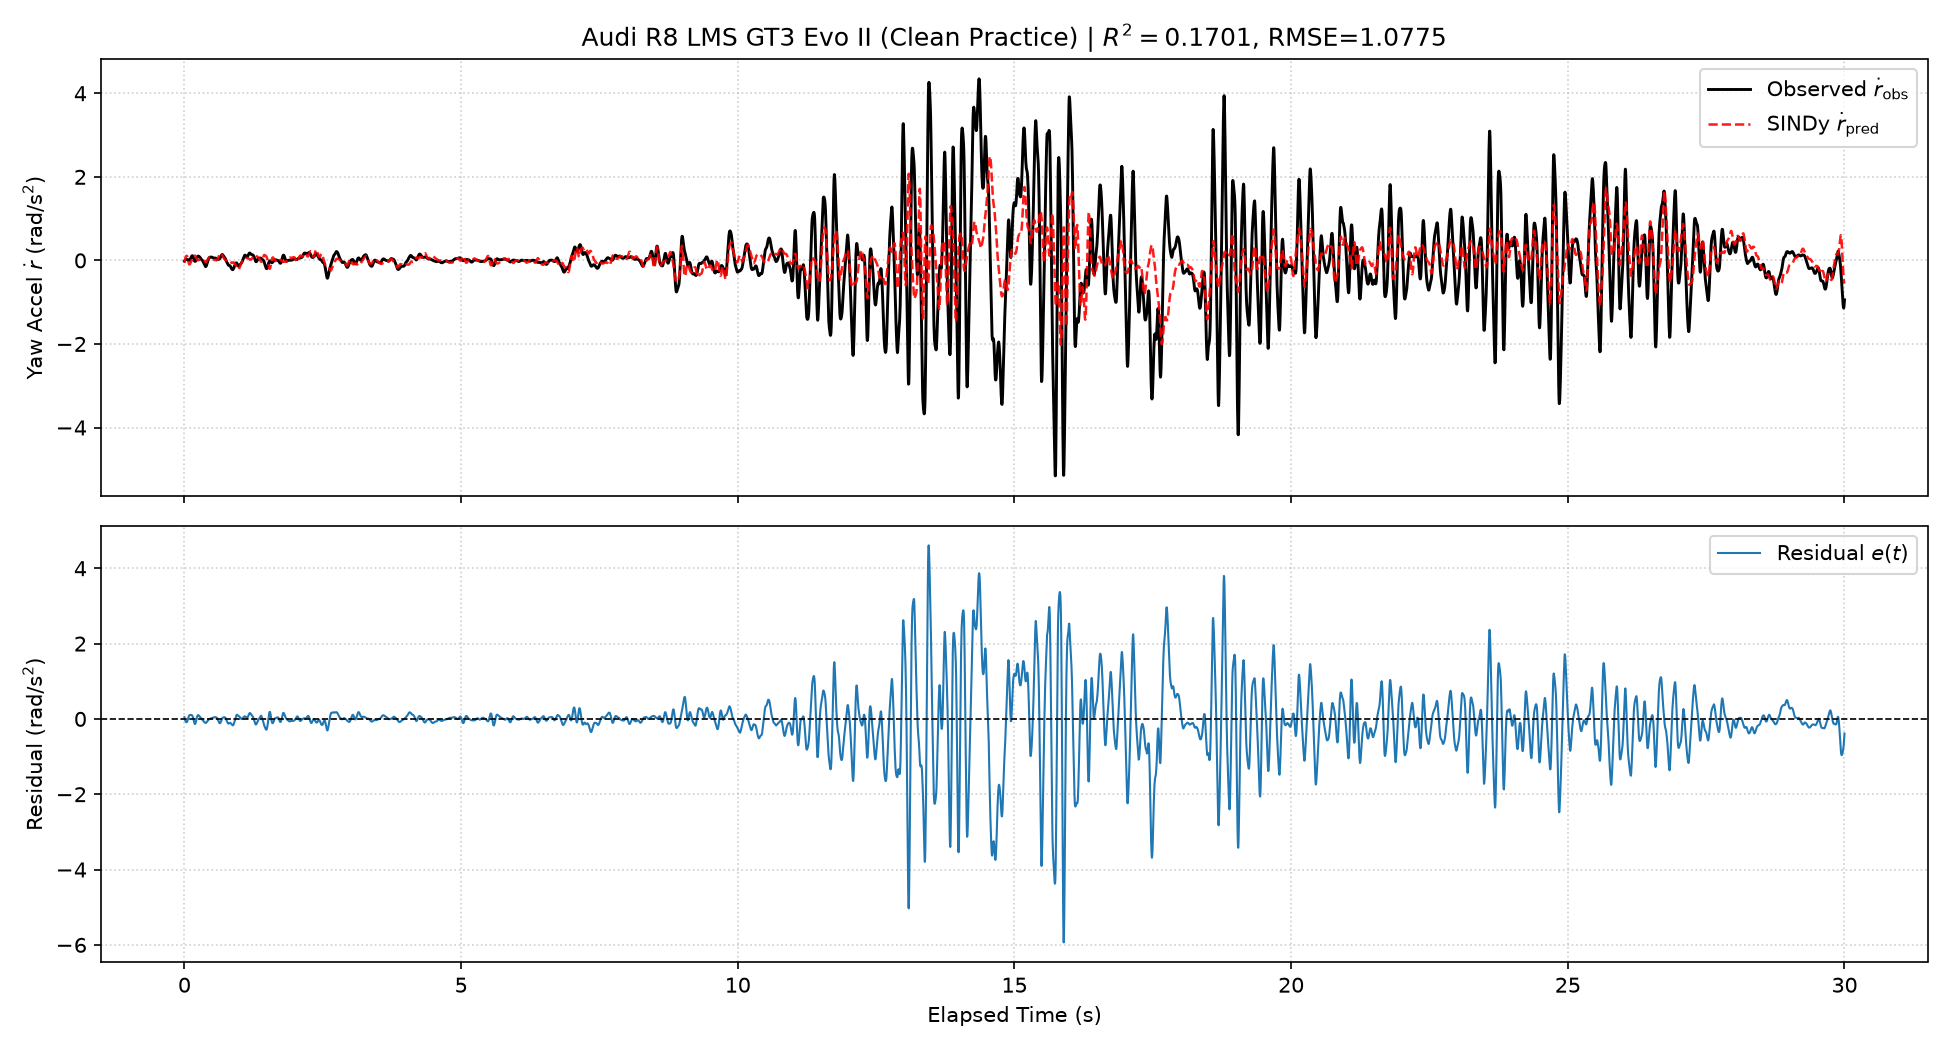

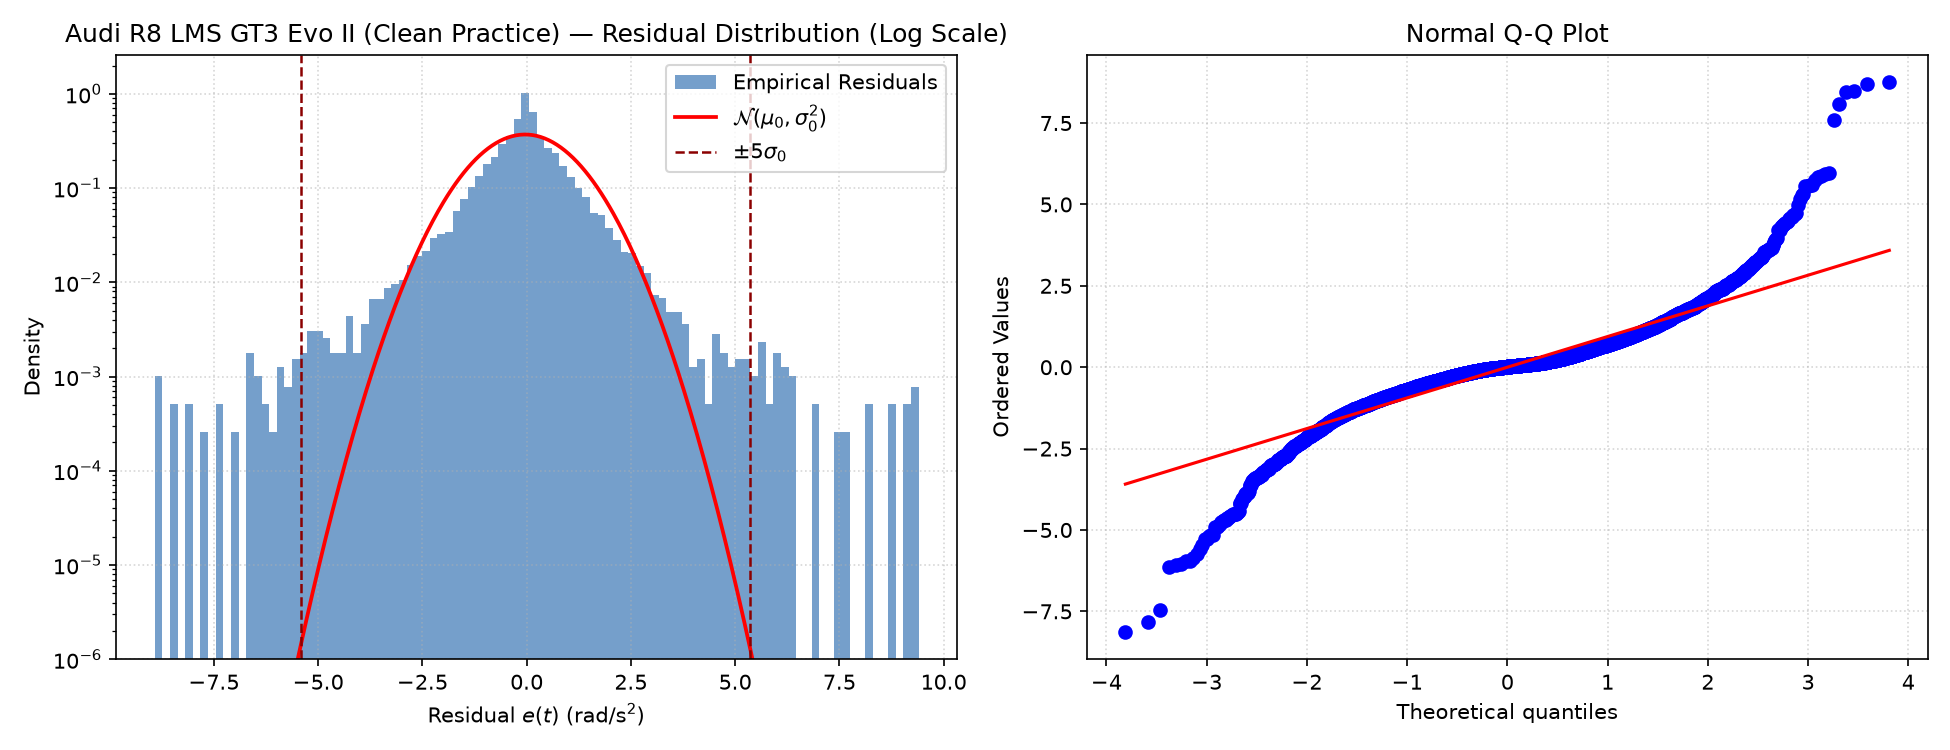

In [4]:
out_dir = Path("outputs") / report["experiment"]
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png"]:
    display(Image(filename=str(out_dir / img_name)))